# Cavity flow, manufactured solutions and grid convergence

This tutorial runs the structured (MAC) solver on the lid-driven cavity, compares it with
Ghia, Ghia & Shin (1982), then checks the order of accuracy with a manufactured solution and
estimates the discretisation error of a quantity of interest with the Grid Convergence Index.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from flowtrace.hardware.backend import get_backend
from flowtrace.structured.case import lid_driven_cavity
from flowtrace.structured.solver import MACSolver
from flowtrace.validation.reference import ghia, compare_ghia

be = get_backend("numba")   # or "numpy" / "cupy"
s = MACSolver(lid_driven_cavity(re=100, n=48), backend=be)
while not s.finished:
    s.step()
    if s.step_count % 10 == 0:
        s.residuals()
print(f"{s.step_count} steps, converged: {s.converged}, max |div u| = {s.max_divergence():.1e}")

3190 steps, converged: True, max |div u| = 5.1e-15


{'u_max_err': 0.004700757342477213, 'u_rms_err': 0.0017046416574197907, 'v_max_err': 0.00801860082905842, 'v_rms_err': 0.004063101725127445}


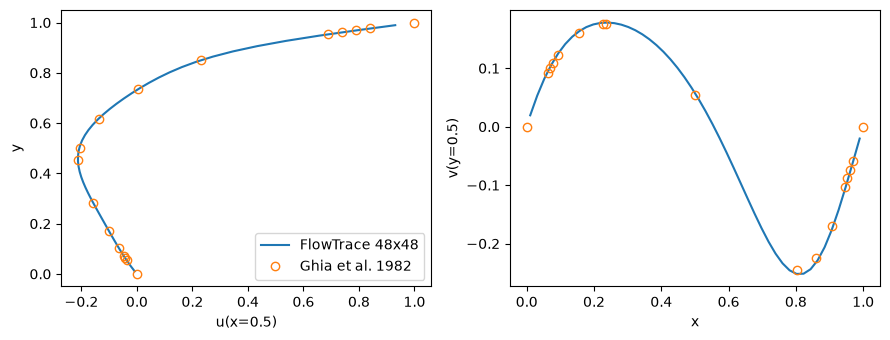

In [2]:
(y, u), (x, v) = s.centerline()
(gy, gu), (gx, gv) = ghia(100)
print(compare_ghia(100, y, u, x, v))
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
ax[0].plot(u, y, label="FlowTrace 48x48"); ax[0].plot(gu, gy, "o", mfc="none", label="Ghia et al. 1982")
ax[0].set_xlabel("u(x=0.5)"); ax[0].set_ylabel("y"); ax[0].legend()
ax[1].plot(x, v); ax[1].plot(gx, gv, "o", mfc="none"); ax[1].set_xlabel("x"); ax[1].set_ylabel("v(y=0.5)")
fig.tight_layout()

## Order of accuracy with a manufactured solution

`run_mac` adds the residual of a known smooth field as a source term and measures the error on
successive grids. Second order means the error drops by 4x when the grid spacing halves.

In [3]:
from flowtrace.validation.mms import run_mac
r = run_mac((16, 32, 64), backend="numba")
for q in r.errors:
    print(f"{q}: L2 errors {['%.2e' % e for e in r.errors[q]]}, observed order {['%.2f' % p for p in r.orders[q]]}")

u: L2 errors ['1.82e-02', '4.45e-03', '1.10e-03'], observed order ['2.03', '2.01']
v: L2 errors ['1.82e-02', '4.45e-03', '1.10e-03'], observed order ['2.03', '2.01']
p: L2 errors ['4.63e-02', '1.17e-02', '2.95e-03'], observed order ['1.98', '1.99']
T: L2 errors ['1.64e-03', '4.08e-04', '1.02e-04'], observed order ['2.00', '2.00']


## Grid Convergence Index

The mean Nusselt number of the differentially heated cavity at Ra = 1e4 on three grids, with the
Richardson-extrapolated value and the GCI (Celik et al. 2008).

In [4]:
from flowtrace.structured.case import natural_convection
from flowtrace.validation.gci import gci
vals, grids = [], (24, 48, 96)
for n in grids:
    sn = MACSolver(natural_convection(ra=1e4, n=n), backend=be)
    while not sn.finished:
        sn.step()
        if sn.step_count % 10 == 0:
            sn.residuals()
    vals.append(sn.nusselt("left"))
g = gci(vals[2], vals[1], vals[0], 1 / 96, 1 / 48, 1 / 24)
print("Nu on 24/48/96:", [round(v, 4) for v in vals])
print(f"observed order {g.observed_order:.2f}, extrapolated Nu {g.extrapolated:.4f} "
      f"(de Vahl Davis 1983: 2.243), GCI_fine {100 * g.gci_fine:.2f} %")

Nu on 24/48/96: [2.2961, 2.2563, 2.2475]
observed order 2.18, extrapolated Nu 2.2450 (de Vahl Davis 1983: 2.243), GCI_fine 0.14 %
